## Mini-Project 2: Ride-Hailing Trip Demand Prediction (Domain: Transportation and Ride-Hailing)

> **Dataset Name:** [NYC TLC Trip Record Data](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page)

This dataset contains information on city taxi trips. The data columns are as follows:

* `trip_distance`: Trip distance (in miles)
* `pickup_datetime`: Date and time of passenger pickup
* `passenger_count`: Number of passengers
* `PULocationID`: Pickup location ID
* `fare_amount`: Base trip fare (target variable)

First, load the dataset and answer the following questions.

### Introductory Level:

1. Parse the `pickup_datetime` feature and create new columns for "hour of the day" and "day of the week."

2. Identify and remove invalid data, such as negative distances or zero fares.

3. Use a boxplot to determine whether trip fares are significantly higher during peak traffic hours.

4. Use a t-test to compare the mean trip fares between weekends and weekdays.

### Advanced Level:

5. Train a **KNN Regressor** model with various values ​​of $K$ and identify the optimal $K$.

6. Train a **Decision Tree** model and visualize its tree structure.

7. Train **Random Forest** and **Linear Regression** models.

8. Apply **PCA** to the pickup and drop-off locations to reduce dimensionality, and analyze its impact on the training speed of the **Random Forest** model.

In [4]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

ModuleNotFoundError: No module named 'pandas'

In [234]:
df = pd.read_parquet("2-data/yellow_tripdata_2026-01-2.parquet", engine="fastparquet")
cleaned_df = df.copy()
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,2,2026-01-01 00:54:04,2026-01-01 00:59:37,1.0,0.97,1.0,N,239,238,1,7.2,1.00,0.5,3.66,0.0,1.0,15.86,2.5,0.0,0.00
1,1,2026-01-01 00:34:04,2026-01-01 00:39:47,0.0,0.90,1.0,N,163,162,2,7.9,4.25,0.5,0.00,0.0,1.0,13.65,2.5,0.0,0.75
2,1,2026-01-01 00:57:06,2026-01-01 01:05:59,0.0,1.40,1.0,N,43,237,1,10.7,4.25,0.5,2.50,0.0,1.0,18.95,2.5,0.0,0.75
3,2,2026-01-01 00:15:22,2026-01-01 00:58:10,4.0,5.58,1.0,N,142,209,1,38.7,1.00,0.5,11.11,0.0,1.0,55.56,2.5,0.0,0.75
4,2,2026-01-01 00:27:13,2026-01-01 00:40:43,0.0,2.16,1.0,N,88,144,1,13.5,1.00,0.5,3.85,0.0,1.0,23.10,2.5,0.0,0.75


In [235]:
df.describe()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
count,150000.000000,150000,150000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000
mean,1.884540,2026-01-02 03:43:53.843806,2026-01-02 03:59:19.710126,1.465700,4.068443,3.935833,160.512873,160.431573,1.268327,20.109446,1.525968,0.466447,3.565553,0.625370,0.931000,29.553719,2.099983,0.191808,0.517730
min,1.000000,2025-12-31 23:57:29,2025-12-31 23:57:32,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,-629.500000,-7.500000,-0.500000,-79.000000,-40.000000,-1.000000,-636.750000,-2.500000,-1.750000,-0.750000
25%,2.000000,2026-01-01 14:53:08.750000,2026-01-01 15:07:03,1.000000,1.000000,1.000000,132.000000,107.000000,1.000000,8.600000,0.000000,0.500000,0.000000,0.000000,1.000000,15.950000,2.500000,0.000000,0.000000
50%,2.000000,2026-01-02 09:23:02,2026-01-02 09:38:12.500000,1.000000,1.780000,1.000000,161.000000,161.000000,1.000000,12.800000,1.000000,0.500000,2.740000,0.000000,1.000000,21.420000,2.500000,0.000000,0.750000
75%,2.000000,2026-01-02 17:01:42,2026-01-02 17:20:47.250000,2.000000,3.940000,1.000000,230.000000,233.000000,1.000000,23.300000,2.500000,0.500000,4.490000,0.000000,1.000000,32.850000,2.500000,0.000000,0.750000
max,7.000000,2026-01-03 07:01:13,2026-01-05 20:44:12,6.000000,36610.270000,99.000000,265.000000,265.000000,4.000000,850.000000,12.500000,0.500000,240.000000,75.880000,1.000000,850.000000,2.500000,20.000000,0.750000
std,0.762058,NaN,NaN,0.873034,94.653084,16.265924,63.768167,70.907679,0.621297,22.205050,1.847893,0.158412,4.567652,2.458677,0.323171,27.000188,1.015932,0.605370,0.367932


In [236]:
df.nunique()

VendorID                     3
tpep_pickup_datetime     92589
tpep_dropoff_datetime    92616
passenger_count              7
trip_distance             2839
RatecodeID                   7
store_and_fwd_flag           2
PULocationID               245
DOLocationID               256
payment_type                 4
fare_amount               1189
extra                       34
mta_tax                      3
tip_amount                2429
tolls_amount               277
improvement_surcharge        3
total_amount              8276
congestion_surcharge         3
Airport_fee                  6
cbd_congestion_fee           3
dtype: int64

In [237]:
df.shape


(150000, 20)

In [238]:
df.columns

Index(['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime',
       'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag',
       'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra',
       'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge',
       'total_amount', 'congestion_surcharge', 'Airport_fee',
       'cbd_congestion_fee'],
      dtype='object')

1.

In [ ]:
cleaned_df["pickup_datetime"] = pd.to_datetime(df["tpep_pickup_datetime"])
cleaned_df["dropoff_datetime"] = pd.to_datetime(df["tpep_dropoff_datetime"])

cleaned_df["pickup_hour"] = cleaned_df["pickup_datetime"].dt.hour
cleaned_df["dropoff_hour"] = cleaned_df["dropoff_datetime"].dt.hour

# Extract the weekday (0 = Monday, 6 = Sunday)
cleaned_df["weekday"] = cleaned_df["pickup_datetime"].dt.weekday
cleaned_df["weekday"] = cleaned_df["dropoff_datetime"].dt.weekday

# Calculate the raw time difference (Returns a Timedelta)
time_difference = cleaned_df["dropoff_datetime"] - cleaned_df["pickup_datetime"]

# Convert the difference strictly into total minutes (as a floating-point number)
cleaned_df["trip_duration_minutes"] = time_difference.dt.total_seconds() / 60

cleaned_df[["pickup_datetime", "dropoff_datetime", "trip_duration_minutes"]].head()


,pickup_datetime,dropoff_datetime,trip_duration_minutes
0,2026-01-01 00:54:04,2026-01-01 00:59:37,5.550000
1,2026-01-01 00:34:04,2026-01-01 00:39:47,5.716667
2,2026-01-01 00:57:06,2026-01-01 01:05:59,8.883333
3,2026-01-01 00:15:22,2026-01-01 00:58:10,42.800000
4,2026-01-01 00:27:13,2026-01-01 00:40:43,13.500000


2.

In [240]:
negative_include_cols = [col for col in df.select_dtypes(include=['number']).columns
                              if df[col].min()<0]
initial_row_count = len(cleaned_df)

print(negative_include_cols)

print(initial_row_count)

['fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee']
150000


In [241]:
cleaned_df = cleaned_df[(cleaned_df[negative_include_cols] >= 0).all(axis=1)]

affected_rows = initial_row_count - len(df)

print(affected_rows)

0


3.

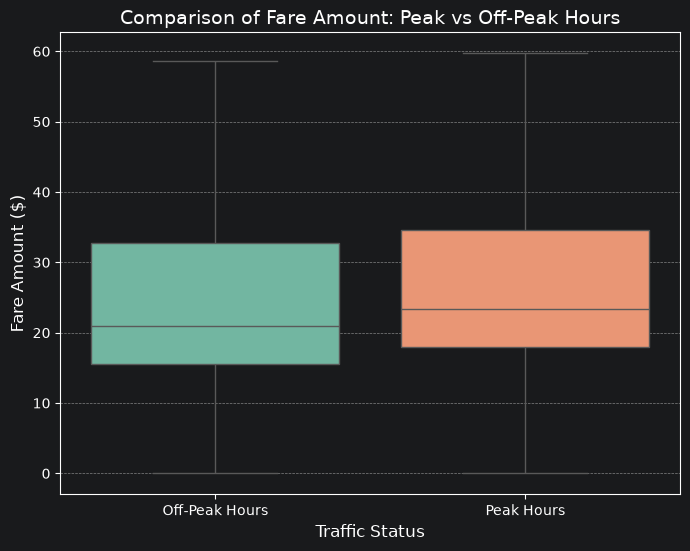

In [242]:
cleaned_df["traffic_status"] = np.where(
    cleaned_df["pickup_hour"].between(16, 20), "Peak Hours", "Off-Peak Hours"
)

plt.figure(figsize=(8, 6))
sns.boxplot(
    data=cleaned_df,
    x="traffic_status",
    y="total_amount",
    hue="traffic_status",
    palette="Set2",
    legend=False,
    showfliers=False,
)

plt.title("Comparison of Fare Amount: Peak vs Off-Peak Hours", fontsize=14)
plt.xlabel("Traffic Status", fontsize=12)
plt.ylabel("Fare Amount ($)", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()


4.

In [ ]:
weekday_fares = cleaned_df[cleaned_df["weekday"] < 5]["fare_amount"]
weekend_fares = cleaned_df[cleaned_df["weekday"] >= 5]["fare_amount"] #5, 6

#Standard Student's t-test (equal_var=True): Assumes both groups have the exact same variance. This is rarely true for real-world data.
# Welch's t-test (equal_var=False): Does not assume equal variances. It modifies the degrees of freedom to account for the differences in spread and sample sizes between your two groups.
t_stat, p_value = stats.ttest_ind(
    weekday_fares, weekend_fares, equal_var=False, nan_policy="omit"
)


print(f"--- T-Test Results ---")
print(f"t-statistic: {t_stat:.4f}")
print(f"p-value: {p_value:.4e}")

alpha = 0.05
if p_value < alpha:
    print(
        "\n نتیجه: تفاوت بین میانگین کرایه روزهای وسط هفته و آخر هفته از نظر آماری کاملاً معنادار است."
    )
    if weekday_fares.mean() > weekend_fares.mean():
        print(
            f"میانگین کرایه وسط هفته (${weekday_fares.mean():.2f}) بیشتر از آخر هفته (${weekend_fares.mean():.2f}) است."
        )
    else:
        print(
            f"میانگین کرایه آخر هفته (${weekend_fares.mean():.2f}) بیشتر از وسط هفته (${weekday_fares.mean():.2f}) است."
        )
else:
    print(
        "\n نتیجه: هیچ تفاوت معنادار آماری بین کرایه روزهای وسط هفته و آخر هفته وجود ندارد (p-value >= 0.05)."
    )

--- T-Test Results ---
t-statistic: -9.4792
p-value: 3.2688e-21

✅ نتیجه: تفاوت بین میانگین کرایه روزهای وسط هفته و آخر هفته از نظر آماری کاملاً معنادار است.
میانگین کرایه آخر هفته ($23.47) بیشتر از وسط هفته ($20.88) است.


In [244]:
cleaned_df.columns

Index(['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime',
       'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag',
       'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra',
       'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge',
       'total_amount', 'congestion_surcharge', 'Airport_fee',
       'cbd_congestion_fee', 'pickup_datetime', 'dropoff_datetime',
       'pickup_hour', 'dropoff_hour', 'weekday', 'trip_duration_minutes',
       'traffic_status'],
      dtype='object')

5. 1:data preprocessing
   2:model training

In [245]:
cols_to_drop = ['VendorID', 'payment_type' , 'mta_tax' , 'Airport_fee' ,'PULocationID', 'DOLocationID', 'tpep_pickup_datetime' , 'tpep_dropoff_datetime' , 'pickup_datetime' , 'dropoff_datetime', 'dropoff_hour' , 'improvement_surcharge' , 'store_and_fwd_flag', 'traffic_status' ,'cbd_congestion_fee']

cleaned_df = cleaned_df.drop(columns=cols_to_drop)

In [246]:
cleaned_df

,passenger_count,trip_distance,RatecodeID,fare_amount,extra,tip_amount,tolls_amount,total_amount,congestion_surcharge,pickup_hour,weekday,trip_duration_minutes
0,1.0,0.97,1.0,7.2,1.00,3.66,0.0,15.86,2.5,0,3,5.550000
1,0.0,0.90,1.0,7.9,4.25,0.00,0.0,13.65,2.5,0,3,5.716667
2,0.0,1.40,1.0,10.7,4.25,2.50,0.0,18.95,2.5,0,3,8.883333
3,4.0,5.58,1.0,38.7,1.00,11.11,0.0,55.56,2.5,0,3,42.800000
4,0.0,2.16,1.0,13.5,1.00,3.85,0.0,23.10,2.5,0,3,13.500000
...,...,...,...,...,...,...,...,...,...,...,...,...
149995,2.0,10.69,1.0,40.1,5.00,0.00,0.0,48.35,0.0,6,5,14.383333
149996,2.0,9.21,1.0,35.2,0.00,0.00,0.0,38.45,0.0,6,5,11.650000
149997,1.0,2.69,1.0,14.9,0.00,2.00,0.0,21.65,2.5,6,5,12.100000
149998,1.0,8.92,1.0,36.6,0.00,0.00,0.0,41.35,2.5,6,5,17.250000


In [247]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

feature_cols = [
    "passenger_count",
    "trip_distance",
    "extra",
    "congestion_surcharge",
    "pickup_hour",
    "weekday",
    "trip_duration_minutes"
]

X = cleaned_df[feature_cols]
y = cleaned_df["fare_amount"]  # Or "total_amount" depending on your target

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Scale only the X features
scaler = StandardScaler()

# Fit learns the mean/variance of training data, then transforms it
X_train_scaled = scaler.fit_transform(X_train)

# ONLY transform the test data using the training parameters
X_test_scaled = scaler.transform(X_test)

K = 1 RMSE is: 12.692551222826525
K = 3 RMSE is: 10.689442892408941
K = 5 RMSE is: 10.516312180447919
K = 7 RMSE is: 10.496772291633556
K = 9 RMSE is: 10.594437222406718
K = 11 RMSE is: 10.775964582509017
K = 15 RMSE is: 10.907996386567927
K = 21 RMSE is: 11.109456257515976
best k is: 7


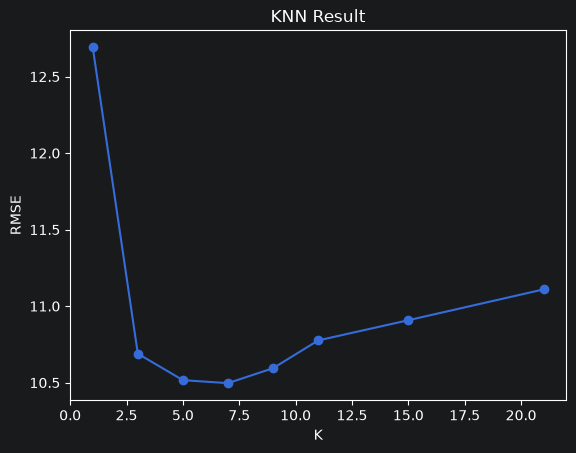

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error


#Standading the featers fro KNN
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#Different K values
k_values = [1, 3, 5, 7, 9, 11, 15, 21]
rmse_values = []

for k in k_values:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)

    y_pred = knn.predict(X_test_scaled)

    mse = mean_squared_error(y_test, y_pred)
    rmse = mse**0.5
    rmse_values.append(rmse)
    print("K =", k, "RMSE is:", rmse)

# Besk K: lowest RMSE
min_rmse = min(rmse_values)
best_k = k_values[rmse_values.index(min_rmse)]
print("best k is:", best_k)

# Plotting
plt.plot(k_values, rmse_values, marker="o")
plt.title("KNN Result")
plt.xlabel("K")
plt.ylabel("RMSE")
plt.show()

6.

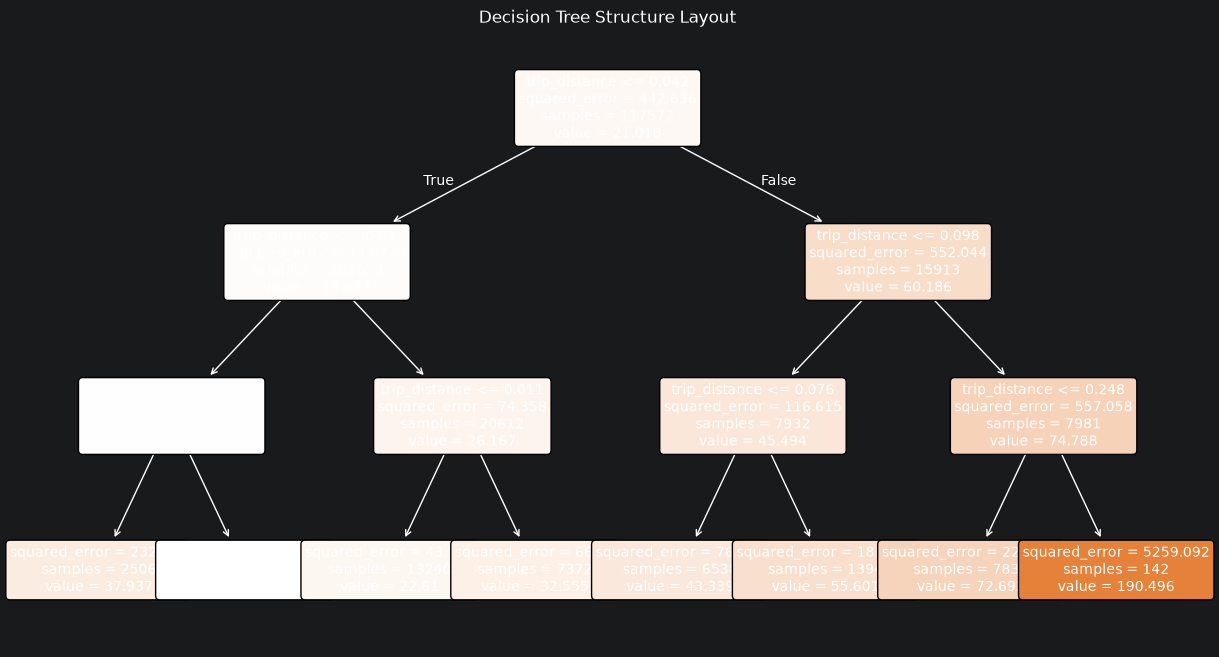

In [249]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

# Train a simple Decision Tree (max_depth=3 keeps the picture readable)
dt_model = DecisionTreeRegressor(max_depth=3, random_state=42)
dt_model.fit(X_train_scaled, y_train)

# Plot the tree structure graphically
plt.figure(figsize=(15, 8))
plot_tree(
    dt_model,
    feature_names=feature_cols,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Structure Layout")
plt.show()


7.

In [250]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# 1. Train Linear Regression Model
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
lr_pred = lr_model.predict(X_test_scaled)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))
print(f"Linear Regression RMSE Error: {lr_rmse:.4f}")

# 2. Train Random Forest Model
rf_model = RandomForestRegressor(n_estimators=50, random_state=42)
rf_model.fit(X_train_scaled, y_train)
rf_pred = rf_model.predict(X_test_scaled)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
print(f"Random Forest RMSE Error: {rf_rmse:.4f}")


Linear Regression RMSE Error: 18.4981
Random Forest RMSE Error: 8.8540


8.

In [ ]:
import time
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

# Pull locations and target
X_locations = df[["PULocationID", "DOLocationID"]]
y_locations = df["fare_amount"]

#Samples & Split
X_loc_sample, _, y_loc_sample, _ = train_test_split(
    X_locations, y_locations, train_size=10000, random_state=42
)

X_loc_train, _, y_loc_train, _ = train_test_split(
    X_loc_sample, y_loc_sample, test_size=0.2, random_state=42
)

# --- Test 1: Training Random Forest WITH Raw Location IDs ---
rf_before_pca = RandomForestRegressor(n_estimators=50, random_state=42)

start_time = time.time()
rf_before_pca.fit(X_loc_train, y_loc_train)
time_before_pca = time.time() - start_time
print(f"Training time with raw location IDs: {time_before_pca:.4f} seconds")

# --- Test 2: Apply PCA to reduce 2 dimensions down to 1 dimension ---
pca = PCA(n_components=1)
X_loc_train_pca = pca.fit_transform(X_loc_train)

# Train Random Forest WITH the single PCA component
rf_after_pca = RandomForestRegressor(n_estimators=50, random_state=42)

start_time = time.time()
rf_after_pca.fit(X_loc_train_pca, y_loc_train)
time_after_pca = time.time() - start_time
print(f"Training time after applying PCA: {time_after_pca:.4f} seconds")

# Calculate the speed difference
speed_improvement = time_before_pca - time_after_pca
print(f"Speed difference: {speed_improvement:.4f} seconds faster/slower")


Training time with raw location IDs: 0.3849 seconds
Training time after applying PCA: 0.4745 seconds
Speed difference: -0.0896 seconds faster/slower


Pearson correlation

In [ ]:
# Compute the Pearson correlation matrix
correlation_matrix = df[numeric_cols].corr(method='pearson')
Set 
# Sort correlations in descending order
target_corr = correlation_matrix['fare_amount'].sort_values(ascending=False)


Simple torch model

In [ ]:
import torch

class TinyModel(torch.nn.Module):

    def __init__(self):
        super().__init__()

        self.linear1 = torch.nn.Linear(12, 50)
        self.activation = torch.nn.RelU()
        self.linear2 = torch.nn.Linear(50, 10)
        self.softmax = torch.nn.RelU(dim=1)

    def forward(self, x):
        x = self.linear1(x)
        x = self.activation(x)
        x = self.linear2(x)
        x = self.activation(x)
        return x

tinymodel = TinyModel()

print('\nModel params:')
for param in tinymodel.parameters():
    print(param)